# Predicitve Modeling for Hospital Length of Stay

- Author: Sydney Sailors
- Date: 2026-11
- Dataset: `meps_los_clean.csv`
- Target: `NUMNIGHX`

In [34]:
# Declare imports
from importlib.metadata import version 
import logging 
import platform 
from typing import Final  

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datafun_toolkit.logger import get_logger, log_header

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_validate

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

LOG: logging.Logger = get_logger("Capstone", level="DEBUG")
log_header(LOG, "Predictive Modeling for Hosptial Length of Stay")

LOG.info("Confirming installation:")
LOG.info(f"  python:       {platform.python_version()}")
LOG.info(f"  pandas:       {version('pandas')}")
LOG.info(f"  numpy:        {version('numpy')}")
LOG.info(f"  scikit-learn: {version('scikit-learn')}")
LOG.info(f"  seaborn:      {version('seaborn')}")
LOG.info(f"  matplotlib:   {version('matplotlib')}")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

2026-11-17 11:53:17 | INFO | Capstone | === RUN START ===
2026-11-17 11:53:17 | INFO | Capstone | project=Predictive Modeling for Hosptial Length of Stay
2026-11-17 11:53:17 | INFO | Capstone | repo_dir=hospital-los-capstone
2026-11-17 11:53:17 | INFO | Capstone | python=3.14.5
2026-11-17 11:53:17 | INFO | Capstone | os=Darwin 20.6.0
2026-11-17 11:53:17 | INFO | Capstone | shell=zsh
2026-11-17 11:53:17 | INFO | Capstone | cwd=notebooks
2026-11-17 11:53:17 | INFO | Capstone | github_actions=False
2026-11-17 11:53:17 | INFO | Capstone | Confirming installation:
2026-11-17 11:53:17 | INFO | Capstone |   python:       3.14.5


2026-11-17 11:53:17 | INFO | Capstone |   pandas:       3.1.0
2026-11-17 11:53:17 | INFO | Capstone |   numpy:        2.5.4
2026-11-17 11:53:17 | INFO | Capstone |   scikit-learn: 1.9.1
2026-11-17 11:53:17 | INFO | Capstone |   seaborn:      0.13.2
2026-11-17 11:53:17 | INFO | Capstone |   matplotlib:   3.11.2


In [35]:
# Load and prepare the data

DATASET_NAME: Final[str] = "Hospital Length of Stay"

LOG.info(f"Loading dataset: {DATASET_NAME}")
df: pd.DataFrame = pd.read_csv("../data/processed/meps_los_clean.csv")
LOG.info(f"Loaded: {df.shape[0]} rows (instances), {df.shape[1]} columns")

FEATURE_COLS = ["AGE24X", "SEX", "RACETHX", "RTHLTH53", "MNHLTH53", "INSCOV24", "REGION24", 
                "EMERROOM", "ANYOPER", "RSNINHOS", "DIABDX_M18", "HIBPDX", "CHDDX", "STRKDX", "ASTHDX"]
TARGET_COL: Final[str] = "NUMNIGHX"

TARGET_LABEL: Final[str] = "Length of Stay (nights)"

X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

groups = df["DUPERSID"]

LOG.info(f"Dataset shape: {df.shape}")
LOG.info(f"Predictor shape: {X.shape}")
LOG.info(f"Target shape: {y.shape}")
LOG.info(f"Number of unique patients: {groups.nunique()}")

print("Missing predictor values:")
print(X.isna().sum())

2026-11-17 11:53:17 | INFO | Capstone | Loading dataset: Hospital Length of Stay
2026-11-17 11:53:17 | INFO | Capstone | Loaded: 1912 rows (instances), 20 columns
2026-11-17 11:53:17 | INFO | Capstone | Dataset shape: (1912, 20)
2026-11-17 11:53:17 | INFO | Capstone | Predictor shape: (1912, 15)
2026-11-17 11:53:17 | INFO | Capstone | Target shape: (1912,)
2026-11-17 11:53:17 | INFO | Capstone | Number of unique patients: 1415


Missing predictor values:
AGE24X         92
SEX             0
RACETHX         0
RTHLTH53      139
MNHLTH53      140
INSCOV24        0
REGION24       92
EMERROOM        0
ANYOPER        19
RSNINHOS       23
DIABDX_M18     15
HIBPDX        125
CHDDX         126
STRKDX        124
ASTHDX         15
dtype: int64


In [36]:
# Split into Train and Test

# Reproducibility for the split and the model
# Pick any integer, but keep it the same to get the same results
RANDOM_STATE: Final[int] = 42

"""
Split X (predictors) and y (target) into training and testing sets.

WHY: Some patients have multiple hospital stays.
GroupShuffleSplit keeps all stays from the same patient
in either the training set or the testing set, but not both.

This helps prevent data leakage.
"""

# Create the grouped train/test splitter
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Declare X_train to hold the training feature values
X_train: pd.DataFrame = X.iloc[train_idx].copy()

# Declare X_test to hold the testing feature values
X_test: pd.DataFrame = X.iloc[test_idx].copy()

# Declare y_train to hold the training target values
y_train: pd.Series = y.iloc[train_idx].copy()

# Declare y_test to hold the testing target values
y_test: pd.Series = y.iloc[test_idx].copy()

# Keep patient identifiers for checking data leakage
groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

# Log the training and testing sizes
LOG.info(f"Train instances: {len(X_train)}")
LOG.info(f"Test instances: {len(X_test)}")

# Check that no patients appear in both sets
patient_overlap = set(groups_train) & set(groups_test)

LOG.info(f"Patients appearing in both sets: {len(patient_overlap)}")


2026-11-17 11:53:18 | INFO | Capstone | Train instances: 1522
2026-11-17 11:53:18 | INFO | Capstone | Test instances: 390
2026-11-17 11:53:18 | INFO | Capstone | Patients appearing in both sets: 0


In [37]:
# Process the Data
# Prepare the numerical and categorical features for modeling

NUMERIC_COLS = ["AGE24X"]

CATEGORICAL_COLS = [
    col for col in FEATURE_COLS
    if col not in NUMERIC_COLS
]

# Preprocessing for numerical variables
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, NUMERIC_COLS),
    ("cat", categorical_transformer, CATEGORICAL_COLS)
])

LOG.info(f"Numerical predictors: {len(NUMERIC_COLS)}")
LOG.info(f"Categorical predictors: {len(CATEGORICAL_COLS)}")
LOG.info("Preprocessing pipeline created successfully.")


2026-11-17 11:53:18 | INFO | Capstone | Numerical predictors: 1
2026-11-17 11:53:18 | INFO | Capstone | Categorical predictors: 14
2026-11-17 11:53:18 | INFO | Capstone | Preprocessing pipeline created successfully.


In [38]:
# Fit a Linear Regression Model

LOG.info("Fitting a linear regression model (scikit-learn)")

# Create a linear regression model object (untrained)
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Fit the model to the training data and retrieve the intercept
model.fit(X_train, y_train)
LOG.info("Linear regression model fitted successfully.")

intercept: float = float(model.named_steps["regressor"].intercept_)
LOG.info(f"Model intercept: {intercept:.4f}")

# Predict length of stay using the test data
y_pred = model.predict(X_test)

LOG.info(f"Generated predictions for {len(y_pred)} hospital stays.")

2026-11-17 11:53:18 | INFO | Capstone | Fitting a linear regression model (scikit-learn)
2026-11-17 11:53:18 | INFO | Capstone | Linear regression model fitted successfully.
2026-11-17 11:53:18 | INFO | Capstone | Model intercept: 5.6030
2026-11-17 11:53:18 | INFO | Capstone | Generated predictions for 390 hospital stays.


In [39]:
# Evaluate Linear Regression

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

LOG.info(f"Linear Regression MAE: {mae:.3f}")
LOG.info(f"Linear Regression RMSE: {rmse:.3f}")
LOG.info(f"Linear Regression R2: {r2:.3f}")

2026-11-17 11:53:18 | INFO | Capstone | Linear Regression MAE: 4.025
2026-11-17 11:53:18 | INFO | Capstone | Linear Regression RMSE: 7.454
2026-11-17 11:53:18 | INFO | Capstone | Linear Regression R2: 0.007


In [40]:
# Validate Linear Regression

LOG.info("Cross-validating Linear Regression")

cv = GroupKFold(n_splits=5)

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=[
        "neg_mean_absolute_error",
        "neg_root_mean_squared_error",
        "r2"
    ]
)

cv_mae = -cv_results["test_neg_mean_absolute_error"].mean()
cv_rmse = -cv_results["test_neg_root_mean_squared_error"].mean()
cv_r2 = cv_results["test_r2"].mean()

LOG.info(f"Cross-Validation MAE: {cv_mae:.3f}")
LOG.info(f"Cross-Validation RMSE: {cv_rmse:.3f}")
LOG.info(f"Cross-Validation R2: {cv_r2:.3f}")

2026-11-17 11:53:18 | INFO | Capstone | Cross-validating Linear Regression
2026-11-17 11:53:19 | INFO | Capstone | Cross-Validation MAE: 3.963
2026-11-17 11:53:19 | INFO | Capstone | Cross-Validation RMSE: 7.918
2026-11-17 11:53:19 | INFO | Capstone | Cross-Validation R2: 0.016


In [41]:
# Fit and Validate a Decision Tree
LOG.info("Fitting Decision Tree Regression")

tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=5,
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(X_train, y_train)

LOG.info("Decision Tree fitted successfully.")

LOG.info("Cross-validating Decision Tree Regression")

tree_cv_results = cross_validate(
    tree_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=[
        "neg_mean_absolute_error",
        "neg_root_mean_squared_error",
        "r2"
    ]
)

tree_cv_mae = -tree_cv_results["test_neg_mean_absolute_error"].mean()
tree_cv_rmse = -tree_cv_results["test_neg_root_mean_squared_error"].mean()
tree_cv_r2 = tree_cv_results["test_r2"].mean()

LOG.info(f"Decision Tree CV MAE: {tree_cv_mae:.3f}")
LOG.info(f"Decision Tree CV RMSE: {tree_cv_rmse:.3f}")
LOG.info(f"Decision Tree CV R2: {tree_cv_r2:.3f}")

2026-11-17 12:47:18 | INFO | Capstone | Fitting Decision Tree Regression
2026-11-17 12:47:18 | INFO | Capstone | Decision Tree fitted successfully.
2026-11-17 12:47:18 | INFO | Capstone | Cross-validating Decision Tree Regression
2026-11-17 12:47:19 | INFO | Capstone | Decision Tree CV MAE: 3.925
2026-11-17 12:47:19 | INFO | Capstone | Decision Tree CV RMSE: 8.761
2026-11-17 12:47:19 | INFO | Capstone | Decision Tree CV R2: -0.223


In [49]:
# Compare Regression Models

LOG.info("Comparing regression models")

# Create a comparison table
comparison_df = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [cv_mae, tree_cv_mae],
    "RMSE": [cv_rmse, tree_cv_rmse],
    "R2": [cv_r2, tree_cv_r2]
})

# Sort by RMSE (lower is better)
comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
)

comparison_df.to_csv("../reports/model_comparison.csv", index=False)

# Display the comparison
print(comparison_df.round(3))

LOG.info("Model comparison completed.")

2026-11-17 14:06:50 | INFO | Capstone | Comparing regression models


2026-11-17 14:06:50 | INFO | Capstone | Model comparison completed.


               Model    MAE   RMSE     R2
0  Linear Regression  3.963  7.918  0.016
1      Decision Tree  3.925  8.761 -0.223


2026-11-17 14:03:11 | INFO | Capstone | Creating actual vs. predicted visualization


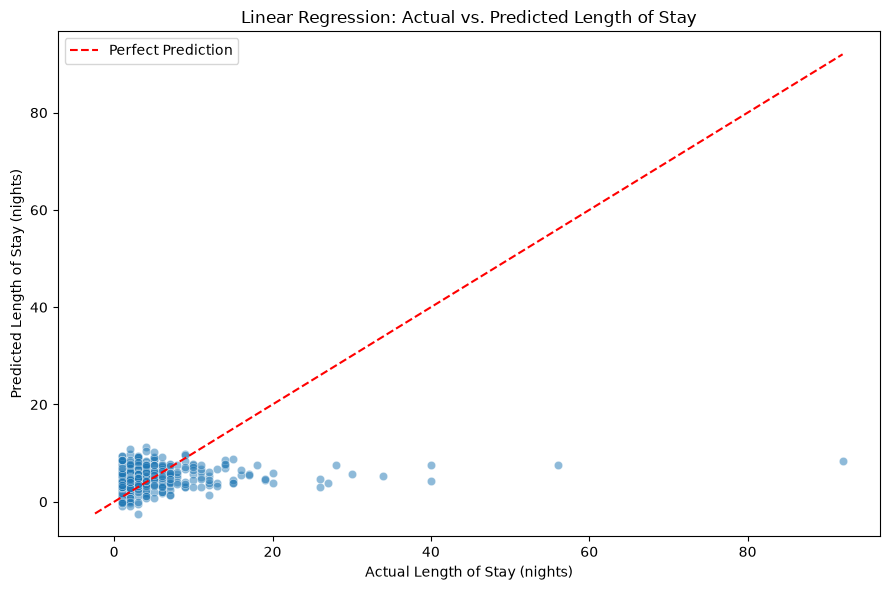

2026-11-17 14:03:12 | INFO | Capstone | Actual vs. predicted visualization completed.


In [47]:
# Visualize Model Predictions

LOG.info("Creating actual vs. predicted visualization")

# Generate predictions using the selected model
y_pred = model.predict(X_test)

# Create scatterplot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.5
)

# Add reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Length of Stay (nights)")
plt.ylabel("Predicted Length of Stay (nights)")
plt.title("Linear Regression: Actual vs. Predicted Length of Stay")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

LOG.info("Actual vs. predicted visualization completed.")

2026-11-17 14:06:24 | INFO | Capstone | Creating residual plot


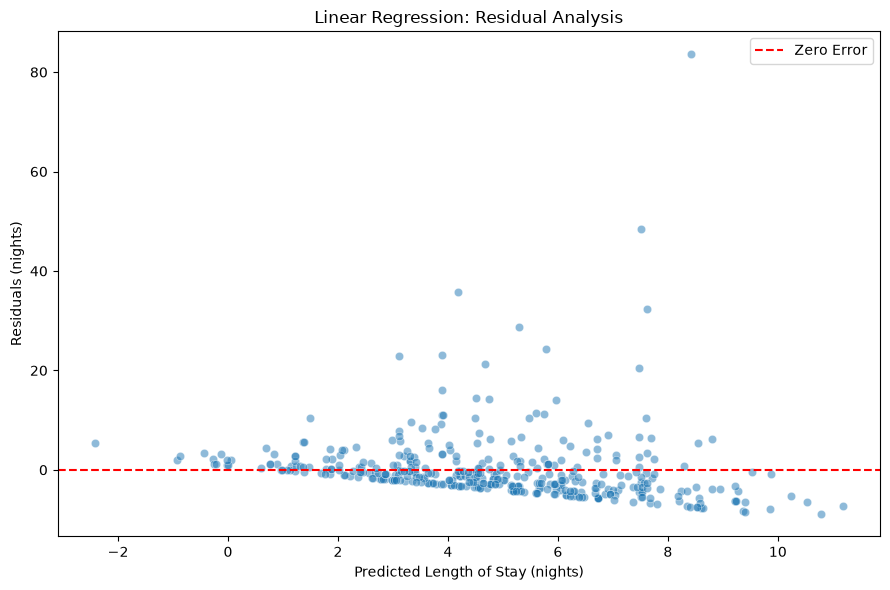

2026-11-17 14:06:25 | INFO | Capstone | Residual analysis completed.


In [48]:
# Residual Analysis

LOG.info("Creating residual plot")

# Calculate residuals
residuals = y_test - y_pred

# Create residual scatterplot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.5
)

# Add reference line at zero residual
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Predicted Length of Stay (nights)")
plt.ylabel("Residuals (nights)")
plt.title("Linear Regression: Residual Analysis")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/residual_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

LOG.info("Residual analysis completed.")